# 1.2 · Conceptos generales de redes neuronales

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/MaxRobles1/deep-learning-equation-to-code/blob/main/topics/01-introduction/1.2-neural-network-basics.ipynb)

**Tiempo estimado:** 40 minutos de lectura · menos de 1 minuto de ejecución.

**Objetivos.** Al terminar esta lección podrás:
1. Describir qué calcula una neurona artificial.
2. Escribir una capa de neuronas en forma matricial.
3. Explicar por qué una red necesita funciones de activación no lineales.
4. Construir una red pequeña en NumPy y en PyTorch, y comprobar que ambas dan el mismo resultado.

**Prerrequisitos.** Producto punto, multiplicación de matrices y la idea de función.

Preparamos el entorno: bibliotecas, semillas y formato de impresión.

In [1]:
import os
from itertools import pairwise

import matplotlib.pyplot as plt
import numpy as np
import torch
from torch import nn

QUICK_MODE = os.environ.get("QUICK_MODE") == "1"  # set by CI; this lesson is fast either way
SEED = 0
rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.dpi"] = 90

## 1 · Intuición

### Una neurona es un votante que pondera evidencias

Imagina que decides si sales a correr. Revisas varias evidencias: ¿hace buen clima?,
¿tienes tiempo?, ¿estás cansado? No todas pesan igual: el clima quizá importa mucho y el
cansancio resta. Sumas las evidencias, cada una con su importancia, y si el total supera
cierto umbral, sales.

Eso es, casi literalmente, una **neurona artificial**: recibe entradas, multiplica cada una
por un **peso** (su importancia), suma todo junto con un **sesgo** (qué tan fácil es
convencerla) y aplica una **función de activación** que decide su respuesta.

### Inspiración, no copia

La idea nació de la biología: McCulloch y Pitts (1943) propusieron un modelo matemático
inspirado en cómo una neurona se activa al recibir suficientes señales. Pero conviene no
exagerar el parecido: una neurona artificial es una operación matemática muy simple, no un
modelo del cerebro.

### De una neurona a una red

- Muchas neuronas que reciben las **mismas entradas** forman una **capa**.
- Varias capas encadenadas, donde la salida de una es la entrada de la siguiente, forman una
  **red neuronal**.

### El problema que lo cambia todo: XOR

XOR ("o exclusivo") responde 1 cuando **exactamente una** de sus dos entradas vale 1:

| $x_1$ | $x_2$ | XOR |
|:---:|:---:|:---:|
| 0 | 0 | 0 |
| 0 | 1 | 1 |
| 1 | 0 | 1 |
| 1 | 1 | 0 |

Parece trivial, pero **una sola neurona no puede calcularlo**. Minsky y Papert (1969)
analizaron esta clase de limitaciones, y su trabajo contribuyó a que el interés por las
redes neuronales decayera durante años. En esta lección vas a ver por qué una neurona falla
y cómo una red de dos capas lo resuelve.

## 2 · Matemática

Usamos la notación del curso ([docs/NOTATION.md](../../docs/NOTATION.md)).

### 2.1 Una neurona

Una neurona con entradas $\mathbf{x} \in \mathbb{R}^d$, pesos $\mathbf{w} \in \mathbb{R}^d$ y
sesgo $b \in \mathbb{R}$ calcula primero una **preactivación** y después su **activación**:

$$z = \mathbf{w}^\top\mathbf{x} + b = \sum_{j=1}^{d} w_j x_j + b, \qquad a = g(z)$$

### 2.2 Funciones de activación

| Nombre | Fórmula | Rango |
|---|---|---|
| Escalón | $H(z) = 1$ si $z \ge 0$; $0$ si no | $\{0, 1\}$ |
| Sigmoide | $\sigma(z) = \dfrac{1}{1 + e^{-z}}$ | $(0, 1)$ |
| Tangente hiperbólica | $\tanh(z) = \dfrac{e^{z} - e^{-z}}{e^{z} + e^{-z}}$ | $(-1, 1)$ |
| ReLU | $\mathrm{ReLU}(z) = \max(0, z)$ | $[0, \infty)$ |

El escalón es el del **perceptrón** de Rosenblatt (1958). Las otras tres son suaves (o casi),
y eso será indispensable para entrenar redes en el Tema 5.

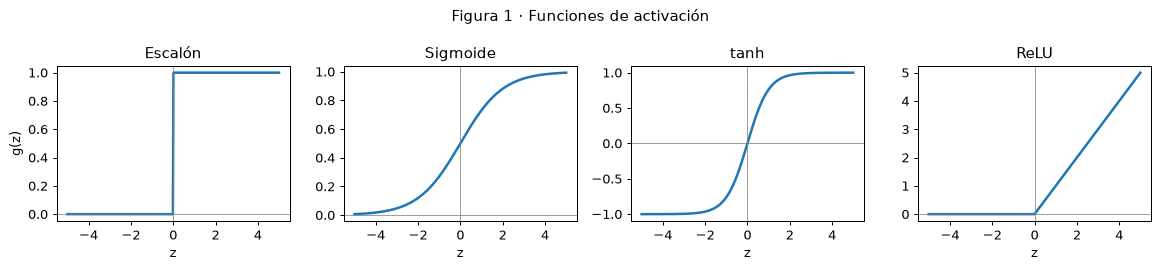

In [2]:
z = np.linspace(-5, 5, 400)
activations = {
    "Escalón": (z >= 0).astype(float),
    "Sigmoide": 1 / (1 + np.exp(-z)),
    "tanh": np.tanh(z),
    "ReLU": np.maximum(0, z),
}

fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharex=True)
for ax, (name, values) in zip(axes, activations.items(), strict=True):
    ax.plot(z, values, color="tab:blue", linewidth=2)
    ax.axhline(0, color="gray", linewidth=0.6)
    ax.axvline(0, color="gray", linewidth=0.6)
    ax.set_title(name)
    ax.set_xlabel("z")
axes[0].set_ylabel("g(z)")
fig.suptitle("Figura 1 · Funciones de activación")
fig.tight_layout()
plt.show()

### 2.3 Lo que una neurona puede (y no puede) separar

Con el escalón, la neurona responde 1 cuando $\mathbf{w}^\top\mathbf{x} + b \ge 0$. La
**frontera de decisión** es

$$\mathbf{w}^\top\mathbf{x} + b = 0,$$

que en dos dimensiones es una **recta** (en general, un hiperplano): $\mathbf{w}$ fija su
orientación y $b$ la desplaza. Por eso una sola neurona solo puede separar clases que se
puedan dividir con una línea recta; se dice que son **linealmente separables**. AND y OR lo
son; XOR no.

### 2.4 Una capa en forma matricial

Una capa con $n_1$ neuronas que reciben la misma entrada $\mathbf{x}$ se escribe de una vez:

$$\mathbf{z}^{[1]} = \mathbf{W}^{[1]}\mathbf{x} + \mathbf{b}^{[1]}, \qquad \mathbf{a}^{[1]} = g(\mathbf{z}^{[1]})$$

donde $\mathbf{W}^{[1]}$ tiene forma $(n_1, d)$: **cada renglón son los pesos de una neurona**.

Para procesar un **lote** de ejemplos a la vez, los apilamos como renglones de una matriz
$\mathbf{X}$ de forma $(B, d)$:

$$\mathbf{Z} = \mathbf{X}\,\mathbf{W}^\top + \mathbf{b}$$

Esta es exactamente la operación que calcula PyTorch; es el puente entre la ecuación y el
código.

### 2.5 Una red de dos capas

Encadenando dos capas:

$$\hat{y} = g^{[2]}\!\left(\mathbf{W}^{[2]}\, g^{[1]}\!\left(\mathbf{W}^{[1]}\mathbf{x} + \mathbf{b}^{[1]}\right) + \mathbf{b}^{[2]}\right)$$

A la primera capa se le llama **oculta** porque sus valores no se observan en los datos: son
una representación intermedia que la red construye.

### 2.6 Por qué hace falta la no linealidad

Si quitamos las activaciones, las dos capas colapsan en una sola:

$$\mathbf{W}^{[2]}\left(\mathbf{W}^{[1]}\mathbf{x} + \mathbf{b}^{[1]}\right) + \mathbf{b}^{[2]}
= \underbrace{\left(\mathbf{W}^{[2]}\mathbf{W}^{[1]}\right)}_{\text{una sola matriz}}\mathbf{x}
+ \underbrace{\left(\mathbf{W}^{[2]}\mathbf{b}^{[1]} + \mathbf{b}^{[2]}\right)}_{\text{un solo sesgo}}$$

Apilar capas lineales no agrega capacidad: el resultado sigue siendo una función lineal. La
activación no lineal entre capas es lo que permite a la red representar fronteras curvas o
quebradas.

### 2.7 Cuántos parámetros tiene una red

Una capa con $n_l$ neuronas y $n_{l-1}$ entradas tiene $n_l \cdot n_{l-1}$ pesos y $n_l$
sesgos. En total:

$$\text{parámetros} = \sum_{l=1}^{L} n_l\,(n_{l-1} + 1)$$

## 3 · Desde cero (NumPy)

Escribimos las piezas con nuestras propias manos. Cada función es una línea de la sección
anterior.

In [3]:
def step(z: np.ndarray) -> np.ndarray:
    """Heaviside step: 1 where z >= 0, otherwise 0."""
    return (z >= 0).astype(float)


def sigmoid(z: np.ndarray) -> np.ndarray:
    """Logistic sigmoid: 1 / (1 + exp(-z))."""
    return 1.0 / (1.0 + np.exp(-z))


def relu(z: np.ndarray) -> np.ndarray:
    """Rectified linear unit: max(0, z)."""
    return np.maximum(0.0, z)


def neuron(x: np.ndarray, w: np.ndarray, b: float, activation) -> np.ndarray:
    """One artificial neuron: g(w . x + b)."""
    return activation(x @ w + b)


def dense(X: np.ndarray, W: np.ndarray, b: np.ndarray, activation) -> np.ndarray:
    """One fully connected layer for a batch (rows of X are examples): g(X W^T + b)."""
    return activation(X @ W.T + b)

### 3.1 Una neurona que calcula AND y otra que calcula OR

Para AND, la neurona solo debe activarse cuando **ambas** entradas valen 1: con pesos
$(1, 1)$, la suma es 2 solo en ese caso, así que basta un sesgo de $-1.5$. Para OR basta que
**alguna** valga 1, así que el sesgo es $-0.5$.

In [4]:
X_bool = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
y_and = np.array([0, 0, 0, 1])
y_or = np.array([0, 1, 1, 1])
y_xor = np.array([0, 1, 1, 0])

w = np.array([1.0, 1.0])
and_output = neuron(X_bool, w, -1.5, step)
or_output = neuron(X_bool, w, -0.5, step)

print("AND:", and_output, "| correct:", np.array_equal(and_output, y_and))
print("OR: ", or_output, "| correct:", np.array_equal(or_output, y_or))

AND: [0. 0. 0. 1.] | correct: True
OR:  [0. 1. 1. 1.] | correct: True


La figura 2 muestra cada frontera. Para XOR dibujamos el mejor intento posible: cualquier
recta deja al menos un punto del lado equivocado.

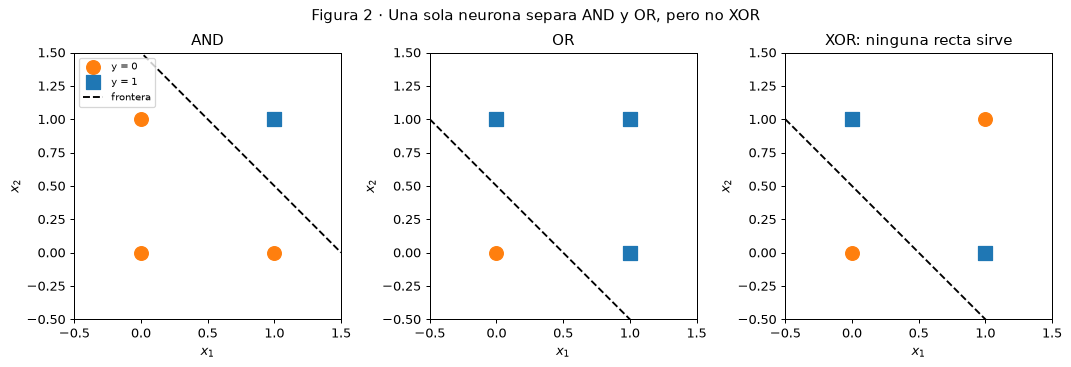

In [5]:
def plot_points(ax, X, y, title):
    """Scatter the four boolean inputs, colored by label."""
    for label, color, marker in [(0, "tab:orange", "o"), (1, "tab:blue", "s")]:
        mask = y == label
        ax.scatter(X[mask, 0], X[mask, 1], c=color, marker=marker, s=120, label=f"y = {label}")
    ax.set_xlim(-0.5, 1.5)
    ax.set_ylim(-0.5, 1.5)
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(title)
    ax.set_aspect("equal")


def plot_boundary(ax, w, b):
    """Draw the line w1*x1 + w2*x2 + b = 0."""
    x1 = np.linspace(-0.5, 1.5, 50)
    ax.plot(x1, -(w[0] * x1 + b) / w[1], color="black", linestyle="--", label="frontera")


fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, (title, y, bias) in zip(
    axes,
    [("AND", y_and, -1.5), ("OR", y_or, -0.5), ("XOR: ninguna recta sirve", y_xor, -0.5)],
    strict=True,
):
    plot_points(ax, X_bool, y, title)
    plot_boundary(ax, w, bias)
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Figura 2 · Una sola neurona separa AND y OR, pero no XOR")
fig.tight_layout()
plt.show()

### 3.2 Una red de dos capas que sí calcula XOR

La clave es descomponer XOR en piezas que una neurona sí puede calcular:

$$\text{XOR}(x_1, x_2) = \text{OR}(x_1, x_2) \ \text{y no} \ \text{AND}(x_1, x_2)$$

- **Capa oculta:** la neurona 1 calcula OR y la neurona 2 calcula AND.
- **Capa de salida:** se activa si OR vale 1 y AND vale 0.

Los pesos se eligen a mano; aprenderlos automáticamente es lo que veremos en el Tema 5.

In [6]:
# Hidden layer: row 1 is the OR neuron, row 2 is the AND neuron.
W1 = np.array([[1.0, 1.0], [1.0, 1.0]])
b1 = np.array([-0.5, -1.5])
# Output layer: "OR and not AND".
W2 = np.array([[1.0, -1.0]])
b2 = np.array([-0.5])

hidden = dense(X_bool, W1, b1, step)
y_hat = dense(hidden, W2, b2, step).ravel()

print(" x1 x2 | OR AND | XOR")
for x, h, out in zip(X_bool, hidden, y_hat, strict=True):
    print(f"  {x[0]:.0f}  {x[1]:.0f} |  {h[0]:.0f}  {h[1]:.0f}  |  {out:.0f}")
print("correct:", np.array_equal(y_hat, y_xor))

 x1 x2 | OR AND | XOR
  0  0 |  0  0  |  0
  0  1 |  1  0  |  1
  1  0 |  1  0  |  1
  1  1 |  1  1  |  0
correct: True


### 3.3 Qué hace realmente la capa oculta

La capa oculta **transforma el espacio**. A la izquierda, los puntos de XOR en su espacio
original: no hay recta que los separe. A la derecha, los mismos puntos después de la capa
oculta, en el espacio $(\text{OR}, \text{AND})$: ahora una recta basta, y esa recta es la
neurona de salida. Observa que $(0, 1)$ y $(1, 0)$ caen en el mismo punto del espacio oculto:
para la red, ambos casos ya son equivalentes. Esta idea, transformar la representación hasta que el problema se vuelve
fácil, es el corazón del aprendizaje profundo.

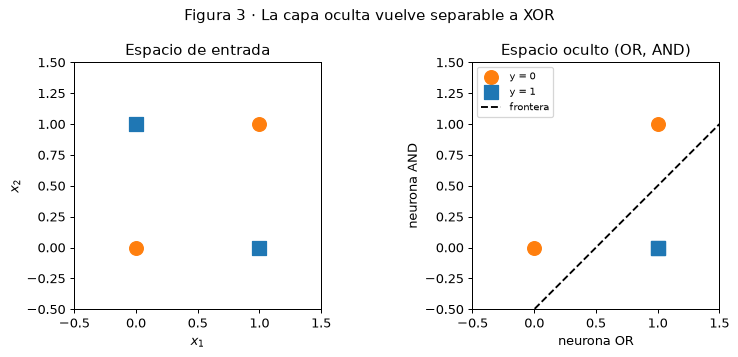

In [7]:
fig, (ax_in, ax_hidden) = plt.subplots(1, 2, figsize=(9, 4))
plot_points(ax_in, X_bool, y_xor, "Espacio de entrada")
plot_points(ax_hidden, hidden, y_xor, "Espacio oculto (OR, AND)")
ax_hidden.set_xlabel("neurona OR")
ax_hidden.set_ylabel("neurona AND")
plot_boundary(ax_hidden, W2[0], b2[0])
ax_hidden.legend(loc="upper left", fontsize=8)
fig.suptitle("Figura 3 · La capa oculta vuelve separable a XOR")
fig.tight_layout()
plt.show()

### 3.4 Contar parámetros

In [8]:
def count_params(layer_sizes: list[int]) -> int:
    """Number of weights and biases of a fully connected network."""
    return sum(n_out * (n_in + 1) for n_in, n_out in pairwise(layer_sizes))


print("XOR network 2 -> 2 -> 1:", count_params([2, 2, 1]), "parameters")

XOR network 2 -> 2 -> 1: 9 parameters


## 4 · Con PyTorch

Construimos la misma red con `torch.nn`. Dos detalles importan:

1. `nn.Linear(entradas, salidas)` guarda sus pesos con forma **(salidas, entradas)** y
   calcula $\mathbf{X}\mathbf{W}^\top + \mathbf{b}$, igual que nuestra función `dense`.
2. PyTorch no trae una capa escalón, y con razón: su derivada es cero en casi todas partes,
   así que no sirve para entrenar. Usamos la **sigmoide**: si multiplicamos pesos y sesgos
   por un número $k$ grande, la sigmoide se comporta casi como un escalón.

In [9]:
print("nn.Linear(2, 3).weight.shape =", tuple(nn.Linear(2, 3).weight.shape), "-> (outputs, inputs)")

model = nn.Sequential(nn.Linear(2, 2), nn.Sigmoid(), nn.Linear(2, 1), nn.Sigmoid())
model

nn.Linear(2, 3).weight.shape = (3, 2) -> (outputs, inputs)


Sequential(
  (0): Linear(in_features=2, out_features=2, bias=True)
  (1): Sigmoid()
  (2): Linear(in_features=2, out_features=1, bias=True)
  (3): Sigmoid()
)

In [10]:
k = 10.0  # a large k makes the sigmoid behave almost like a step

with torch.no_grad():
    model[0].weight.copy_(torch.tensor(k * W1))
    model[0].bias.copy_(torch.tensor(k * b1))
    model[2].weight.copy_(torch.tensor(k * W2))
    model[2].bias.copy_(torch.tensor(k * b2))
    y_torch = model(torch.tensor(X_bool, dtype=torch.float32)).numpy().ravel()

y_numpy = dense(dense(X_bool, k * W1, k * b1, sigmoid), k * W2, k * b2, sigmoid).ravel()

print("NumPy:  ", y_numpy)
print("PyTorch:", y_torch)
print("max difference:", np.abs(y_numpy - y_torch).max())
print("same result:", np.allclose(y_numpy, y_torch, atol=1e-6))
print("rounded output equals XOR:", np.array_equal(np.round(y_torch), y_xor))

NumPy:   [0.0072 0.9924 0.9924 0.0072]
PyTorch: [0.0072 0.9924 0.9924 0.0072]
max difference: 4.0654893895819555e-08
same result: True
rounded output equals XOR: True


In [11]:
n_torch = sum(p.numel() for p in model.parameters())
print("parameters in PyTorch:", n_torch, "| by our formula:", count_params([2, 2, 1]))

parameters in PyTorch: 9 | by our formula: 9


La diferencia máxima es menor que $10^{-7}$: NumPy calcula en `float64` y PyTorch en
`float32`. Las dos implementaciones calculan exactamente la misma función.

## 5 · Experimenta

### 5.1 Busca una recta para XOR

Mueve los deslizadores para cambiar los pesos y el sesgo de una sola neurona. Comprobarás que
ninguna combinación separa los cuatro puntos. Los deslizadores funcionan al ejecutar el
notebook (en Colab o en tu computadora); en GitHub solo se ve el código.

In [12]:
try:
    from ipywidgets import FloatSlider, interact
except ImportError:  # pragma: no cover
    interact = None


def try_single_neuron(w1: float = 1.0, w2: float = 1.0, b: float = -0.5) -> None:
    """Plot one neuron's boundary over the XOR points and count its mistakes."""
    weights = np.array([w1, w2])
    predictions = neuron(X_bool, weights, b, step)
    _, ax = plt.subplots(figsize=(4, 4))
    plot_points(ax, X_bool, y_xor, f"Errores: {int((predictions != y_xor).sum())} de 4")
    if abs(w2) > 1e-9:
        plot_boundary(ax, weights, b)
    plt.show()


if interact is not None:
    slider = {"min": -3.0, "max": 3.0, "step": 0.1}
    interact(
        try_single_neuron,
        w1=FloatSlider(value=1.0, **slider),
        w2=FloatSlider(value=1.0, **slider),
        b=FloatSlider(value=-0.5, **slider),
    )

### 5.2 Del escalón a la sigmoide

La figura 4 muestra $\sigma(kz)$ para varios valores de $k$. Prueba otros valores en la
celda: cuanto mayor es $k$, más se parece la sigmoide al escalón.

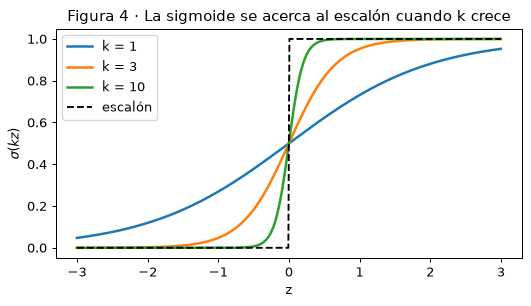

In [13]:
z = np.linspace(-3, 3, 400)
fig, ax = plt.subplots(figsize=(6, 3.5))
for k_value in [1, 3, 10]:
    ax.plot(z, sigmoid(k_value * z), linewidth=2, label=f"k = {k_value}")
ax.plot(z, step(z), color="black", linestyle="--", label="escalón")
ax.set_xlabel("z")
ax.set_ylabel(r"$\sigma(kz)$")
ax.set_title("Figura 4 · La sigmoide se acerca al escalón cuando k crece")
ax.legend()
fig.tight_layout()
plt.show()

## 6 · Errores comunes

- **Olvidar la activación entre capas.** La red entera colapsa en una función lineal
  (sección 2.6), sin importar cuántas capas tenga.
- **Confundir la orientación de los pesos.** En PyTorch, `nn.Linear(2, 3).weight` tiene forma
  `(3, 2)`: un renglón por neurona de salida.
- **Un sesgo con la forma equivocada.** NumPy y PyTorch aplican *broadcasting* sin avisar: un
  sesgo de forma `(B, 1)` en lugar de `(n,)` produce resultados absurdos sin lanzar error.
- **Mezclar `float64` y `float32`.** NumPy usa `float64` por omisión y PyTorch `float32`;
  convierte explícitamente al pasar de uno a otro.
- **Tomar la analogía biológica al pie de la letra.** Una neurona artificial es una suma
  ponderada seguida de una función, no un modelo del cerebro.

## 7 · Ejercicios

**Ejercicio 1.** Una neurona tiene pesos $\mathbf{w} = (0.5, -1, 2)$ y sesgo $b = -1$.
Calcula a mano su salida para $\mathbf{x} = (2, 1, 0.5)$ con activación sigmoide y con ReLU.
Después verifica tus resultados con la función `neuron`.

In [14]:
# Ejercicio 1: tu código aquí


**Ejercicio 2.** ¿Cuántos parámetros tiene una red totalmente conectada con capas
784 → 128 → 64 → 10? (Es una arquitectura típica para clasificar los dígitos de MNIST.)
Calcúlalo con la fórmula de la sección 2.7 y compruébalo construyendo la red en PyTorch.

In [15]:
# Ejercicio 2: tu código aquí


**Ejercicio 3.** Genera matrices aleatorias $\mathbf{W}^{[1]}$, $\mathbf{W}^{[2]}$ y
sesgos $\mathbf{b}^{[1]}$, $\mathbf{b}^{[2]}$, y comprueba numéricamente que dos capas sin
activación equivalen a una sola capa con $\mathbf{W} = \mathbf{W}^{[2]}\mathbf{W}^{[1]}$ y
$\mathbf{b} = \mathbf{W}^{[2]}\mathbf{b}^{[1]} + \mathbf{b}^{[2]}$.

In [16]:
# Ejercicio 3: tu código aquí


**Ejercicio 4.** Encuentra pesos y sesgo para que una sola neurona con escalón calcule
NAND (el AND negado). Explica con tus palabras, usando la idea de frontera de decisión, por
qué no existen pesos que hagan que una sola neurona calcule XOR.

In [17]:
# Ejercicio 4: tu código aquí


**Ejercicio 5.** Construye una red de dos capas que calcule XOR usando **ReLU** en la
capa oculta (la salida puede seguir usando el escalón). Verifica tu red con los cuatro
casos.

In [18]:
# Ejercicio 5: tu código aquí


## 8 · Para profundizar

- **Nielsen (2015), capítulo 1:** perceptrones, neuronas sigmoides y la arquitectura de una red.
- **Goodfellow, Bengio y Courville (2016), capítulo 6, sección 6.1:** el ejemplo de XOR.
- **Prince (2023), capítulo 3:** redes neuronales poco profundas.

Artículos originales:
- McCulloch, W. S. y Pitts, W. (1943). A logical calculus of the ideas immanent in nervous activity. *Bulletin of Mathematical Biophysics*, 5(4), 115–133.
- Rosenblatt, F. (1958). The perceptron: A probabilistic model for information storage and organization in the brain. *Psychological Review*, 65(6), 386–408.
- Minsky, M. y Papert, S. (1969). *Perceptrons: An Introduction to Computational Geometry*. MIT Press.

Referencias completas en [SYLLABUS.md](../../SYLLABUS.md) y [docs/REFERENCES.md](../../docs/REFERENCES.md).

---
*Texto y figuras: [CC BY 4.0](../../LICENSE-CONTENT). Código: [MIT](../../LICENSE).*